In [1]:
import numpy as np
import librosa as lr
import scipy as sp
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import HTML

from filters import *

In [2]:
y, sr = lr.load("../data/audio/s13.wav", sr=None)

Text(0, 0.5, 'level [dB]')

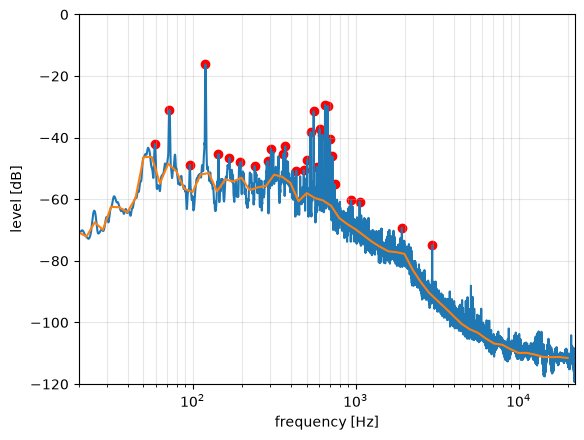

In [3]:
nperseg = 2**16

# spectrum and decibel conversion
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# find peaks
peaks, _ = sp.signal.find_peaks(db, prominence=12, height=-80)
peak_freq, peak_db = quad_interp(f, db, peaks)
peak_width = sp.signal.peak_widths(P, peaks, rel_height=0.5)
peak_df = pl.DataFrame(
    {
        "idx": peaks,
        "peak_spec_freq": f[peaks],
        "peak_spec_db": db[peaks],
        "peak_spec_pow": P[peaks],
        "peak_freq": peak_freq,
        "peak_db": peak_db,
        "peak_spec_width": peak_width[0] * np.diff(f)[0] / (sr / nperseg),
    }
)

# fit the floor as medians across log-spaced bins
bin_centers = 1000 * 10 ** (np.arange(-34, 28) / 20)
# edges halfway (in log) between the centers, which are 1/20 decade apart
bins = bin_centers / 10**0.025
floor = sp.stats.binned_statistic(f, db, statistic="median", bins=bins)[0]

# plot spectrum
plt.semilogx(f, db, label="spectrum")

# plot found peaks
plt.scatter(f[peaks], db[peaks], color="red")

# plot the "floor"
plt.semilogx(bin_centers[:-1], floor, label="floor")

plt.xlim(20, sr / 2)
plt.ylim(-120, 0)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("level [dB]")

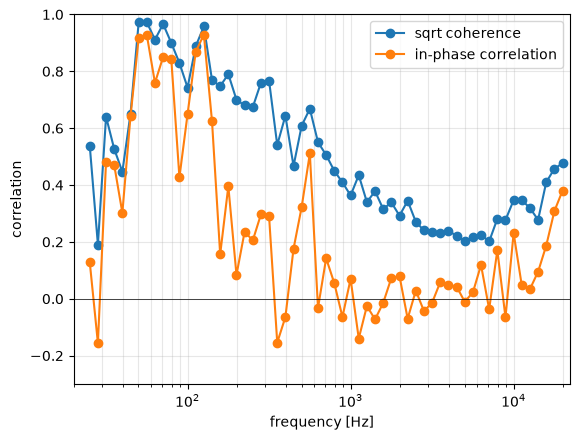

In [19]:
# look at channel correlations
n = 2**16
# look at squared coherence
f_c, C = sp.signal.coherence(y[0], y[1], fs=sr, nperseg=n)
# and cross power spectral density to compute correlation
_, Pxy = sp.signal.csd(y[0], y[1], fs=sr, nperseg=n)
_, Pxx = sp.signal.welch(y[0], fs=sr, nperseg=n)
_, Pyy = sp.signal.welch(y[1], fs=sr, nperseg=n)

# bin it again
per_band = lambda v: sp.stats.binned_statistic(f_c, v, statistic="median", bins=bins)[0]
# this should give similarity at any phase
coh = per_band(C)
# and this should give similarity of phase (signed)
r = per_band(Pxy.real / np.sqrt(Pxx * Pyy))

plt.semilogx(bin_centers[:-1], np.sqrt(coh), "o-", label="sqrt coherence")
plt.semilogx(bin_centers[:-1], r, "o-", label="in-phase correlation")
plt.axhline(0, color="k", lw=0.5)
plt.ylim(-0.3, 1)
plt.xlim(20, sr / 2)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("correlation")
plt.legend()

# ok, again we can basically approximate it as 
# fau.lowcorr(130, 0.85) : fau.lowcorr(700, 0.25)
# from the blue lines (see faust code for (manual) computation of 0.85, 0.25 correlations)
# (im ignoring the orange peak at 500Hz because i don't want to deal with it)

In [36]:
y, sr = lr.load(
    "../data/audio/s13.wav", sr=None, mono=False
)

nperseg = 2**16
bin_centers = 1000 * 10 ** (np.arange(-32, 28) / 20)
# edges halfway (in log) between the centers, which are 1/20 decade apart
bins = bin_centers / 10**0.025

# spectrum of both channels at once, shape (2, freqs)
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# recompute the spectrum as "density", shape (2, freqs)
grid = 20 * 2 ** (np.arange(0, 24 * np.log2(20_000 / 20)) / 24)
smooth = lambda d: np.array(
    [
        np.median(d[(f_d >= c * 2 ** (-1 / 12)) & (f_d <= c * 2 ** (1 / 12))])
        for c in grid
    ]
)
f_d, P_d = sp.signal.welch(y, fs=sr, window="hann", nperseg=nperseg, scaling="density")

floor_curves = [smooth(10 * np.log10(P_d[ch] + 1e-30)) for ch in range(2)]
mean_curve = smooth(10 * np.log10(P_d.mean(axis=0) + 1e-30))

# spectrum is flat-ish after 10k so let's put separate white noise channel as an approximation
hiss = np.array([np.median(c[grid > 14_000]) for c in floor_curves])
# mean db to ass hiss back
hiss_mean = 10 * np.log10(np.mean(10 ** (hiss / 10)))

# recall that separate white noise means adding/subtracting in power not db
remove_hiss = lambda c, h: 10 * np.log10(np.clip(10 ** (c / 10) - 10 ** (h / 10), 1e-30, None))
add_hiss = lambda c, h: 10 * np.log10(10 ** (c / 10) + 10 ** (h / 10))

room_curves = [remove_hiss(c, h) for c, h in zip(floor_curves, hiss)]
room_mean = remove_hiss(mean_curve, 10 * np.log10(np.mean(10 ** (hiss / 10))))

# we will fit only on bins where there IS signal amove the noise
ok = mean_curve > 10 * np.log10(np.mean(10 ** (hiss / 10))) + 3
grid[ok].max()

np.float64(9390.121402415833)

In [30]:
def filter_chain(hipass_freq, alpha1, knee1, alpha2, knee2, alpha3, sr=44_100):
    return sos(
        # hi-pass at very low frequencies
        sp.signal.butter(2, hipass_freq, fs=sr, output="sos", btype="highpass"),
        spectral_tilt(4, 50, knee1 - 50, alpha1 / 2, sr),
        spectral_tilt(4, 50, knee1 - 50, alpha1 / 2, sr),
        spectral_tilt(6, knee1, knee2 - knee1, alpha2 / 2, sr),
        spectral_tilt(6, knee1, knee2 - knee1, alpha2 / 2, sr),
        spectral_tilt(6, knee2, 6000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 6000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 6000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 6000 - knee2, alpha3 / 4, sr),
    )


def model(p, f, sr=44_100):
    (
        *chain_params,
        chain_gain,
    ) = p

    # no.noise has a flat power in dB/Hz
    wn = 10 * np.log10(2 / (3 * sr))

    return wn + db_curve(filter_chain(*chain_params), f) + chain_gain

RMS error 2.60 dB
True `ftol` termination condition is satisfied.



array([ 5.60906549e+01, -9.12326078e-15,  5.57025592e+02, -1.98000000e+00,
        1.94134668e+03, -3.08547485e+00, -5.54963695e+00])

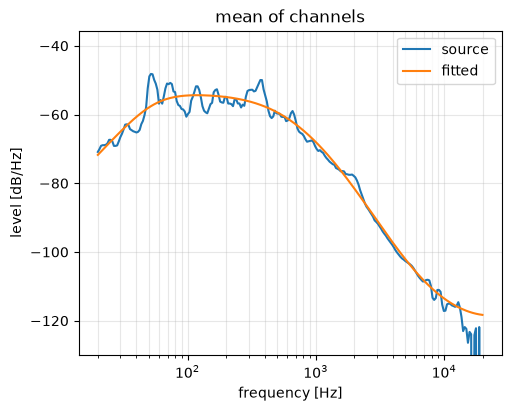

In [34]:


x0 =    [35,  -0.5, 350,  -0.5, 2000,  -0.5, -40]
lower = [25, -1.98, 150, -1.98, 1000, -3.98, -80]
upper = [80,     0, 650,     0, 4500,     0,   0]


fit = sp.optimize.least_squares(
    lambda p, t, f: model(p, f) - t,
    x0,
    bounds=(lower, upper),
    x_scale="jac",
    args=(room_mean[ok], grid[ok]),
)


print(f"RMS error {np.sqrt(np.mean(fit.fun**2)):.2f} dB")
print(fit.success, fit.message)
print()

fig, ax = plt.subplots(1, figsize=(5, 4), layout="constrained")
ax.semilogx(grid, room_mean, label="source")
ax.semilogx(grid, model(fit.x, grid), label="fitted")
ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("level [dB/Hz]")
ax.legend()
ax.set_title("mean of channels")
_, ymax = ax.get_ylim()
ax.set_ylim(-130,ymax)

fit.x

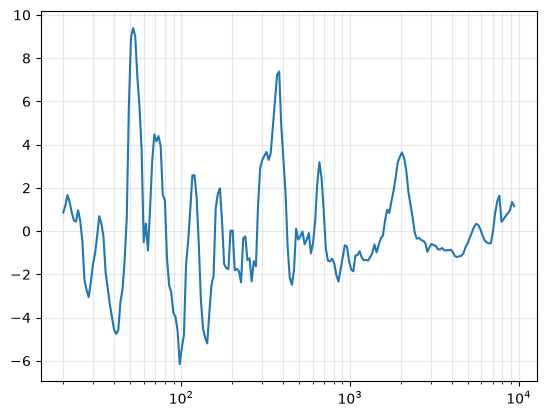

In [33]:
# this is the residual that we can fit with peaking eq filters!
resid = room_mean - model(fit.x, grid)
room_resid, room_grid = resid[ok], grid[ok]
plt.semilogx(room_grid, room_resid)
plt.grid(True, which="both", alpha=0.3)

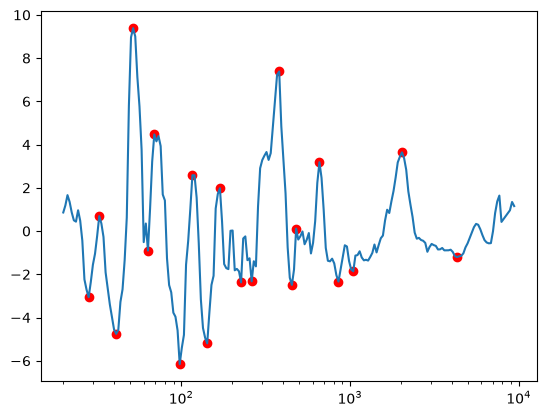

In [35]:
# find positive and negative peaks
bells0 = []
ks = []
for sign in (1, -1):
    k, props = sp.signal.find_peaks(sign * room_resid, prominence=1, width=3)
    # bandwidth at half prominence
    bw = props["widths"] / 24  # octaves at half prominence
    # bandwidth in octaves to Q unit change
    q = 1 / (2 * np.sinh(np.log(2) / 2 * bw))
    bells0 += zip(room_grid[k], q, sign * props["prominences"])
    ks.extend(k)
bells0 = np.array(sorted(bells0))

plt.semilogx(grid[ok], resid[ok])
plt.scatter(grid[ks], resid[ks], color="red")

RMS error 0.58 dB
True `xtol` termination condition is satisfied.



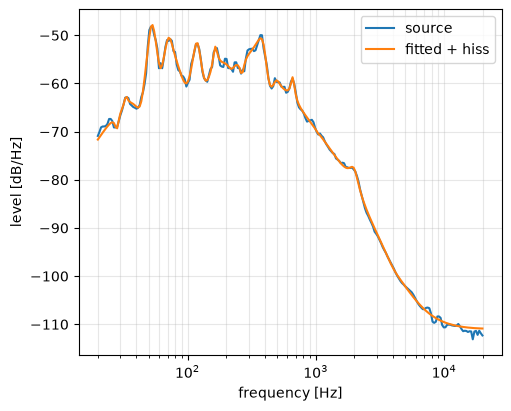

In [37]:
# fit gains, qs, freqs to resid of the mean of channels
def bell_curve(p, f):
    return db_curve(sos(*[bell(fc, q, g) for fc, q, g in np.reshape(p, (-1, 3))]), f)


# bounds are set tight with freq within a tone, q within observed bandwidth
lo = np.ravel([(fc * 2 ** (-1 / 12), q / 2, min(0, 2 * g)) for fc, q, g in bells0])
hi = np.ravel([(fc * 2 ** (1 / 12), q * 2, max(0, 2 * g)) for fc, q, g in bells0])

bell_fit = sp.optimize.least_squares(
    lambda p, t, f: bell_curve(p, f) - t,
    np.ravel(bells0),
    bounds=(lo, hi),
    x_scale="jac",
    args=(room_resid, room_grid),
)

print(f"RMS error {np.sqrt(np.mean(bell_fit.fun**2)):.2f} dB")
print(bell_fit.success, bell_fit.message)
print()

# evaluate

fig, ax = plt.subplots(1, figsize=(5, 4), layout="constrained")

ax.semilogx(grid, mean_curve, label="source")
ax.semilogx(grid, add_hiss(model(fit.x, grid) + bell_curve(bell_fit.x, grid), hiss_mean), label="fitted + hiss")
ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("level [dB/Hz]")
ax.legend()


In [38]:
# now adjust stereo parameters
# keep everything but gains fixed, but adjust gains to match the stereo spectrum better
fc, q, g = np.reshape(bell_fit.x, (-1, 3)).T

# drop bells that go to 0db
keep = np.abs(g) > 0.1
fc, q, g = fc[keep], q[keep], g[keep]

def channel_curve(p, f):
    return p[0] + bell_curve(np.ravel(np.column_stack([fc, q, p[1:]])), f)

lo = np.concatenate([[-20], np.minimum(0, 3 * g)])
hi = np.concatenate([[20], np.maximum(0, 3 * g)])

channel_fits = []
for ch in range(2):
    channel_fit = sp.optimize.least_squares(
        lambda p, t, f: channel_curve(p, f) - t,
        np.concatenate([[0], g]),
        bounds=(lo, hi),
        x_scale="jac",
        args=(room_curves[ch][ok] - model(fit.x, grid[ok]), grid[ok]),
    )
    print(f"{'LR'[ch]} channel: RMS error {np.sqrt(np.mean(channel_fit.fun**2)):.2f} dB, offset {channel_fit.x[0]:+.2f} dB")
    channel_fits.append(channel_fit.x)

# finally adjust offsets and save fit...
names = ["hipassFreq", "alpha1", "knee1", "alpha2", "knee2", "alpha3"]

smooth_params = dict(
    zip(names, fit.x[:-1]),
    chainGainL=fit.x[-1] + channel_fits[0][0],
    chainGainR=fit.x[-1] + channel_fits[1][0],
    hissL=hiss[0],
    hissR=hiss[1],
)
pl.DataFrame([smooth_params]).write_csv("../data/room-13-fit.csv")

# and bells
pl.DataFrame({"freq": fc, "q": q, "gainL": channel_fits[0][1:], "gainR": channel_fits[1][1:]}).write_csv("../data/room-13-bells.csv")

L channel: RMS error 0.82 dB, offset +0.53 dB
R channel: RMS error 0.83 dB, offset +0.29 dB


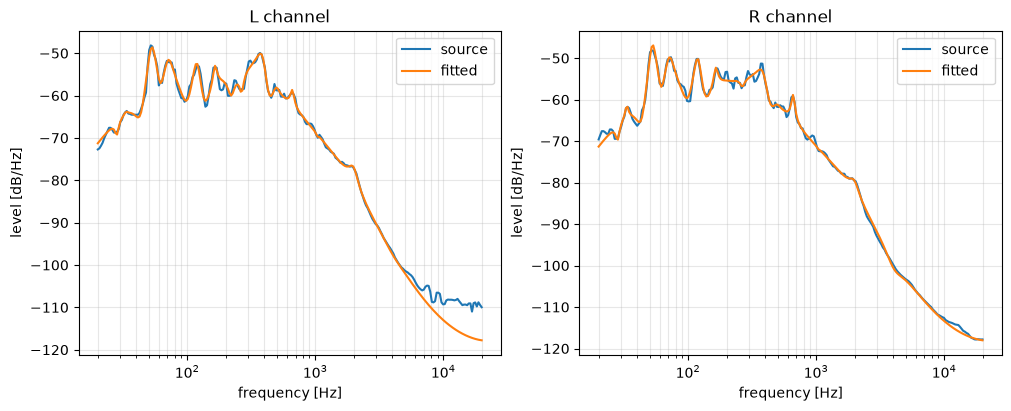

In [39]:
# evaluate stereo match

fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ch, ax in enumerate(axs):
    ax.semilogx(grid, floor_curves[ch], label="source")
    ax.semilogx(grid, model(fit.x, grid) + channel_curve(channel_fits[ch], grid), label="fitted")
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("frequency [Hz]")
    ax.set_ylabel("level [dB/Hz]")
    ax.legend()
    ax.set_title(f"{'LR'[ch]} channel")

In [40]:
# now finally deal with the tones
# let's fit them with phases per-channel because we want to 
# somehow capture their stereo width (esp around the 400-700 cluster)

y, sr = lr.load(
    "../data/audio/s13.wav", sr=None, mono=False
)

nperseg = 2**16
bin_centers = 1000 * 10 ** (np.arange(-32, 28) / 20)
# edges halfway (in log) between the centers, which are 1/20 decade apart
bins = bin_centers / 10**0.025

# spectrum of both channels at once, shape (2, freqs)
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# tones: need one peak freq but separate gains
found = [sp.signal.find_peaks(db[ch], prominence=12, height=-80)[0] for ch in range(2)]


# merge peaks closer than 8 points apart

# first sort and find all unique ones
thresh = 8
peaks = []
for k in np.sort(np.concatenate(found)):
    if not peaks or k - peaks[-1] > thresh:
        peaks.append(k)


# then get levels from each channel at the max
def tone_level(d, k):
    # channel max near the peak
    j = k - thresh + np.argmax(d[k - thresh : k + thresh + 1])
    # if we are at edge then peak missing :(,
    # read raw value for gain, omit freq
    if abs(j - k) == thresh:
        return np.nan, d[k]
    # interpolate as above
    return quad_interp(f, d, j)


tones = []
for k in peaks:
    freqs, gains = [], []
    for ch in range(2):
        # is there a peak found in the channel
        near = found[ch][np.abs(found[ch] - k) <= thresh]
        if len(near):
            # interpolate as above at loudest nearby point
            freq, gain = quad_interp(f, db[ch], near[np.argmax(db[ch][near])])
            freqs.append(freq)
        else:
            # peak missing in this channel :( read "peak" value for gain, omit freq
            gain = db[ch][k]
        gains.append(gain)

    tones.append({"freq": np.mean(freqs), "gainL": gains[0], "gainR": gains[1]})

tone_df = pl.DataFrame(tones)

# csd again to give us the offset of one channel against the other
f_x, Pxy = sp.signal.csd(y[0], y[1], fs=sr, window="hann", nperseg=2**16)

phase = np.angle(
    # get the angle of csd which is literally the phase difference...
    Pxy[ 
        # at the nearest bin to the tone 
        np.argmin(
            np.abs(f_x[:, None] - tone_df["freq"].to_numpy()), axis=0)
        ]
)
tone_df = tone_df.with_columns(phase=phase)

tone_df.write_csv("../data/room-13-tones.csv")
